<a href="https://colab.research.google.com/github/knight19720208ui/AI/blob/main/1_Supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje Supervisado:

| # | Algoritmo | Python puro | scikit-learn |
|---|-----------|:-----------:|:------------:|
| 1 | Regresión Lineal | si | si (California Housing) |
| 2 | Regresión Logística | si | si (Breast Cancer) |
| 3 | KNN | si | si (Iris) |
| 4 | Árbol de Decisión | si | si (Iris) |
| 5 | Naive Bayes | si | si (Iris) |

## Conceptos generales previos

- **Conjunto de entrenamiento / test**: dividimos los datos en dos. El modelo aprende del primero y se evalua en el segundo, qué no ha visto, para medir su capacidad de **generalizar** (no solo memorizar).
- **Overfitting (sobreajuste)**: el modelo aprende tan bien los datos de entrenamiento qué falla con datos nuevos.
- **Validación cruzada (k-fold)**: divide los datos en k partes, entrena en k-1 y evalua en la restante, rotando. Devuelve una estimación más estable del rendimiento.


## Configuración inicial

Ejecutar la siguiente celda **antes de empezar**. Instala las librerias necesarias y carga todos los imports Qué se usaran a lo largo del cuaderno:
- **numpy**: cálculo numérico y generación de datos sintéticos.
- **matplotlib** + **matplotlib.animation**: GRÁFICAs estaticas y Animaciónes.
- **plotly**: GRÁFICAs interactivas (especialmente útiles en Colab).
- **pandas**: manipulación de datasets.
- **scikit-learn**: modelos de machine learning y datasets reales.
- **IPython.display**: para mostrar Animaciónes dentro del cuaderno.


In [17]:
# === Instalación de dependencias ===
# En Colab la mayoria ya están instaladas; esto es por seguridad
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "numpy", "matplotlib", "plotly", "pandas", "scikit-learn"])

# === Imports globales ===
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib import rc
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from collections import Counter
from IPython.display import HTML, display
import warnings
warnings.filterwarnings('ignore')

# Imports específicos de scikit-learn (se cargan aquí para tenerlos disponibles)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, mean_squared_error, r2_score,
                             classification_report, adjusted_rand_score,
                             silhouette_score)
from sklearn.decomposition import PCA as SkPCA

# Configuración de matplotlib para Animaciónes en Colab/Jupyter
rc('animation', html='jshtml')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

# Reproducibilidad
np.random.seed(42)

# Verificación
print("Entorno listo. Versiones:")
print(f"  NumPy:        {np.__version__}")
print(f"  Pandas:       {pd.__version__}")
print(f"  Matplotlib:   {matplotlib.__version__ if False else __import__('matplotlib').__version__}")
print(f"  Plotly:       {__import__('plotly').__version__}")
import sklearn
print(f"  scikit-learn: {sklearn.__version__}")


Entorno listo. Versiones:
  NumPy:        2.4.6
  Pandas:       2.2.3
  Matplotlib:   3.10.0
  Plotly:       5.24.1
  scikit-learn: 1.6.1


# Glosario de métricas para aprendizaje supervisado

Antes de los ejemplos, definimos las métricas Qué se usaran. Cada una aparece **una sola vez** aquí.

## Para regresión (salida continua)

- **MSE (Error Cuadrático Medio)**: promedio de los errores al cuadrado. Penaliza mas los errores grandes.
  $$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
  Mientras mas bajo, mejor. Esta en unidades al cuadrado (ej. "dolares^2").

- **RMSE (raíz del MSE)**: raíz cuadrada del MSE. Vuelve a las unidades originales (mas interpretable).
  $$\text{RMSE} = \sqrt{\text{MSE}}$$

- **R^2 (Coeficiente de determinación)**: proporción de la varianza de y explicada por el modelo.
  $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
  Rango: $(-\infty, 1]$. $R^2=1$ es predicción perfecta; $R^2=0$ es predecir la media; $R^2<0$ es peor que la media.

## Para clasificación (salida categórica)

- **Accuracy (exactitud)**: fracción de predicciones correctas.
  $$\text{Accuracy} = \frac{\text{aciertos}}{\text{total}}$$
  Útil cuando las clases están balanceadas. Si una clase es minoritaria, puede enganar (ej. 95% de la clase mayoritaria => siempre predecir "mayoria" da 95% de accuracy).

- **Matriz de confusión**: tabla qué cuenta Verdaderos Positivos (VP), Falsos Positivos (FP), Verdaderos Negativos (VN) y Falsos Negativos (FN).

- **Precision**: de los qué predije como positivos, cuantos lo eran realmente.
  $$\text{Precision} = \frac{VP}{VP + FP}$$

- **Recall (exhaustividad / sensibilidad)**: de los positivos reales, cuantos encontre.
  $$\text{Recall} = \frac{VP}{VP + FN}$$

- **F1-score**: media armonica de precisión y recall. Útil cuando hay que balancear ambos.
  $$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
  Rango $[0, 1]$. $F_1=1$ es perfecto. La media armónica castiga si alguno de los dos es muy bajo.

- **Gini (impureza de Gini)**: mide cuan mezcladas están las clases en un nodo de árbol. $G = 1 - \sum p_i^2$. $G=0$ nodo puro. Se usa para elegir el mejor corte en árboles.

- **Ganancia de información**: reducción de impureza al dividir un nodo en dos. Se elige el corte qué maximiza está ganancia.


# [PY] 1.1 Regresión Lineal -- Python puro

## Ejemplo

Imaginen qué trabajan en una inmobiliaria y quieren estimar el precio de una casa a partir de sus metros cuadrados. Tienen 50 datos históricos (m^2, precio). Quieren encontrar la recta: $y = w \cdot x + b$, que mejor se ajuste.

## Qué se aprende

- Como se formula el problema como minimización de una función de pérdida (MSE).
- Como funciona el **gradiente descendente**: iterativamente, calculamos la derivada del error respecto a cada parámetro y damos un paso en dirección contraria.
- Por qué es importante **normalizar las features** antes del gradiente descendente (sin normalizar, el learning rate puede hacer diverger el algoritmo).

## Idea matemática

La función de pérdida es el MSE: $L(w, b) = \frac{1}{n} \sum (w x_i + b - y_i)^2$.

Las derivadas parciales son:
- $\nabla_w = \frac{2}{n} \sum x_i (\hat{y}_i - y_i)$
- $\nabla_b = \frac{2}{n} \sum (\hat{y}_i - y_i)$

Actualización: $w \leftarrow w - \eta \nabla_w$, donde $\eta$ es el learning rate.

## Dataset sintético

Precio de casa (miles de dolares) vs. metros cuadrados. Generaremos $y = 0.5 + 0.8 \cdot X + \text{ruido}$ y veremos si el algoritmo recupera $w \approx 0.8$ y $b \approx 0.5$.


In [18]:
# === 1.1 REGRESIÓN LINEAL -- Python puro ===
# Datos sintéticos: metros cuadrados -> precio (miles $)
np.random.seed(42)
n = 50
X = np.random.uniform(40, 200, n)                    # 40 a 200 m^2
y_true = 0.5 + 0.8 * X + np.random.normal(0, 15, n)  # y = 0.5 + 0.8*X + ruido

# Normalizamos X para Qué el gradiente descendente sea estable
X_mean, X_std = X.mean(), X.std()
X_norm = (X - X_mean) / X_std

# Inicializacion de parámetros
w, b = 0.0, 0.0
lr = 0.1                  # learning rate (alto porQué X está normalizada)
epochs = 100

# Historial para visualizar la convergencia
history_w, history_b, history_loss = [], [], []

for epoch in range(epochs):
    y_pred = w * X_norm + b
    error = y_pred - y_true
    loss = np.mean(error**2)   # MSE

    # Gradientes
    grad_w = (2/n) * np.sum(X_norm * error)
    grad_b = (2/n) * np.sum(error)

    # Actualización
    w -= lr * grad_w
    b -= lr * grad_b

    history_w.append(w)
    history_b.append(b)
    history_loss.append(loss)

# Convertir parámetros al espacio original (des-normalizar w)
w_orig = w / X_std
b_orig = b - w_orig * X_mean
print(f"Parámetros aprendidos: w={w_orig:.4f} (esperado aprox 0.8), b={b_orig:.4f} (esperado aprox 0.5)")
print(f"MSE final: {history_loss[-1]:.2f}")


Parámetros aprendidos: w=0.7791 (esperado aprox 0.8), b=2.7882 (esperado aprox 0.5)
MSE final: 185.19


In [19]:
# === GRÁFICA: evolución del ajuste ===
# Animación: como la recta converge a los datos a lo largo de las epocas

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X, y_true, c='#1f77b4', alpha=0.6, label='Datos reales')
line, = ax.plot([], [], 'r-', lw=2, label='Recta aprendida')
ax.set_xlim(30, 210); ax.set_ylim(0, 200)
ax.set_xlabel('Metros cuadrados'); ax.set_ylabel('Precio (miles $)')
ax.set_title('Regresión Lineal -- convergencia del gradiente descendente')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)

def init():
    line.set_data([], [])
    return line,

def update(frame):
    # Convertir parámetros normalizados al espacio original
    wi_norm, bi_norm = history_w[frame], history_b[frame]
    wi = wi_norm / X_std
    bi = bi_norm - wi * X_mean
    xs = np.linspace(30, 210, 100)
    line.set_data(xs, wi*xs + bi)
    ax.set_title(f'Epoca {frame}/{epochs-1} | w={wi:.3f}, b={bi:.3f}, MSE={history_loss[frame]:.2f}')
    return line,

anim = animation.FuncAnimation(fig, update, frames=range(0, epochs, 2),
                               init_func=init, blit=True, interval=60)
plt.close()
HTML(anim.to_jshtml())


# [SK] 1.2 Regresión Lineal -- scikit-learn

## Ejemplo

Mismo problema, pero ahora con un dataset real: **California Housing**, qué contiene el precio medio de viviendas por bloque censal en California (unas 20.640 filas con 8 features). Usaremos 3 features relevantes: ingreso medio, antiguedad de la vivienda y número medio de habitaciones.

## Qué se aprende

- Qué scikit-learn resuelve el mismo problema en **3 lineas** (`fit`, `predict`, `score`).
- Qué la libreria maneja por nosotros la normalización y el cálculo cerrado (sin iteraciones).
- Qué el $R^2$ es la métrica tipica para evaluar regresión.

## Diferencia clave con la version Python puro

Aquí el modelo encuentra la solución óptima directamente (minimos cuadrados via descomposicion SVD), no iterativamente. La convergencia del gradiente descendente era un truco pedagogico; en producción se usa la solución cerrada.


In [20]:
# === 1.2 REGRESIÓN LINEAL -- scikit-learn ===
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression

# Dataset real: California Housing
data = fetch_california_housing(as_frame=True)
X_real = data.data[['MedInc', 'HouseAge', 'AveRooms']]   # 3 features relevantes
y_real = data.target                                      # precio medio (centenas de miles $)

X_train, X_test, y_train, y_test = train_test_split(X_real, y_real, test_size=0.2, random_state=42)

# 3 lineas y listo!
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Coeficientes: {dict(zip(X_train.columns, model.coef_.round(3)))}")
print(f"Intercepto: {model.intercept_:.3f}")
print(f"MSE: {mse:.3f} | R^2: {r2:.3f}")


Coeficientes: {'MedInc': np.float64(0.445), 'HouseAge': np.float64(0.017), 'AveRooms': np.float64(-0.028)}
Intercepto: 0.017
MSE: 0.659 | R^2: 0.497


In [21]:
# === GRÁFICA: predicción vs. real con Plotly ===
df_plot = pd.DataFrame({'Real': y_test.values[:200], 'Predicho': y_pred[:200]})

fig = px.scatter(df_plot, x='Real', y='Predicho',
                 title='Regresión Lineal (sklearn) -- California Housing: Real vs Predicho',
                 labels={'Real': 'Valor real', 'Predicho': 'Valor predicho'},
                 opacity=0.6, template='plotly_white',
                 color_discrete_sequence=['#2ca02c'])
# Linea y = x (predicción perfecta)
fig.add_trace(go.Scatter(x=[df_plot.Real.min(), df_plot.Real.max()],
                         y=[df_plot.Real.min(), df_plot.Real.max()],
                         mode='lines', name='Prediccion perfecta',
                         line=dict(color='red', dash='dash')))
fig.show()


# [PY] 1.3 Regresión Logística -- Python puro

## Ejemplo

Son profesores y quieren predecir si un estudiante aprobara un examen según las horas qué estudio. La salida no es un número continuo, sino **0 (reprueba) o 1 (aprueba)**. La regresión lineal no funciona aquí: necesitamos qué la salida este en [0, 1] para interpretarla como probabilidad.

## Qué se aprende

- La **función sigmoid** $\sigma(z) = 1/(1 + e^{-z})$, qué mapea cualquier número real al intervalo (0, 1).
- La **pérdida logarítmica (cross-entropy binaria)**, qué es la función de pérdida adecuada para clasificación binaria.
- Por qué no se puede usar MSE en clasificación (no es convexa en este contexto).

## Idea matemática

- Prediccion: $\hat{y} = \sigma(w x + b) = \frac{1}{1 + e^{-(wx+b)}}$
- Pérdida binaria cruzada: $L = -\frac{1}{n} \sum [y \log \hat{y} + (1-y)\log(1-\hat{y})]$
- Gradiente: identico al de regresión lineal pero con $\hat{y} - y$ (gracias a la propiedad de la sigmoid + cross-entropy).

## Dataset sintético

Horas de estudio (0-15h) -> aprobado (1) / reprobado (0). La probabilidad real oculta es $\sigma(0.8x - 5)$.


In [22]:
# === 1.3 REGRESIÓN Logística -- Python puro ===
np.random.seed(42)
n = 80
X = np.random.uniform(0, 15, n)                      # horas de estudio 0-15
prob_real = 1 / (1 + np.exp(-(0.8 * X - 5)))        # función sigmoide real
y = (np.random.rand(n) < prob_real).astype(int)     # etiQuéta 0/1

# Inicializacion
w, b = 0.0, 0.0
lr = 0.05
epochs = 500

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))   # clip para estabilidad numerica

history_loss, history_w, history_b = [], [], []

for epoch in range(epochs):
    z = w * X + b
    y_pred = sigmoid(z)

    # Pérdida binaria cruzada (cross-entropy)
    eps = 1e-9
    loss = -np.mean(y * np.log(y_pred + eps) + (1-y) * np.log(1 - y_pred + eps))

    # Gradientes
    error = y_pred - y
    grad_w = np.mean(X * error)
    grad_b = np.mean(error)

    w -= lr * grad_w
    b -= lr * grad_b

    history_loss.append(loss)
    history_w.append(w)
    history_b.append(b)

print(f"w={w:.4f}, b={b:.4f}, pérdida final={history_loss[-1]:.4f}")

# Accuracy
preds = (sigmoid(w * X + b) >= 0.5).astype(int)
acc = np.mean(preds == y)
print(f"Accuracy: {acc*100:.1f}%")


w=0.4103, b=-2.5067, pérdida final=0.3055
Accuracy: 90.0%


In [23]:
# === GRÁFICA: Animación de la sigmoid convergiendo ===
fig, ax = plt.subplots(figsize=(9, 5))

def update(frame):
    ax.clear()
    wi, bi = history_w[frame], history_b[frame]
    xs = np.linspace(-1, 16, 200)
    ys = sigmoid(wi * xs + bi)
    ax.scatter(X[y==0], y[y==0], c='red', s=80, edgecolors='k', label='Reprobado')
    ax.scatter(X[y==1], y[y==1], c='green', s=80, edgecolors='k', label='Aprobado')
    ax.plot(xs, ys, 'b-', lw=2, label=f'sigma({wi:.2f}*x + {bi:.2f})')
    ax.axhline(0.5, color='gray', ls='--', alpha=0.5)
    ax.set_xlim(-1, 16); ax.set_ylim(-0.1, 1.1)
    ax.set_xlabel('Horas de estudio'); ax.set_ylabel('P(aprobado)')
    ax.set_title(f'Regresión Logística -- epoca {frame} | pérdida={history_loss[frame]:.3f}')
    ax.legend(loc='upper left'); ax.grid(alpha=0.3)

anim = animation.FuncAnimation(fig, update, frames=range(0, epochs, 10),
                               interval=80, blit=False)
plt.close()
HTML(anim.to_jshtml())


# [SK] 1.4 Regresión Logística -- scikit-learn

## Ejemplo

Diagnóstico médico: predecir si un tumor de mama es **maligno** o **benigno** a partir de 30 características extraidas de imágenes digitales de biopsias (dataset Breast Cancer Wisconsin, 569 muestras).

## Qué se aprende

- A aplicar la métrica **F1-score** en un problema real (no solo accuracy), porQué en medicina los falsos negativos son muy costosos (decir "benigno" cuando es maligno).
- A leer un **classification_report** Qué muestra precisión, recall y F1 por clase.
- A **normalizar features** con `StandardScaler`: la regresión Logística (como muchos modelos lineales) funciona mejor con features en escalas similares.


In [24]:
# === 1.4 REGRESIÓN Logística -- scikit-learn ===
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

data = load_breast_cancer()
X = data.data[:, :2]  # usamos 2 features para poder GRÁFICAr (mean radius, mean texture)
y = data.target       # 0=maligno, 1=benigno

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

clf = LogisticRegression(max_iter=2000)
clf.fit(X_train_s, y_train)
y_pred = clf.predict(X_test_s)

print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.1f}%")
print()
print("Reporte de clasificación (precisión / recall / F1 por clase):")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 88.3%

Reporte de clasificación (precisión / recall / F1 por clase):
              precision    recall  f1-score   support

   malignant       0.87      0.81      0.84        64
      benign       0.89      0.93      0.91       107

    accuracy                           0.88       171
   macro avg       0.88      0.87      0.87       171
weighted avg       0.88      0.88      0.88       171



In [25]:
# === GRÁFICA: frontera de decisión interactiva con Plotly ===
# Crear malla
x_min, x_max = X_train_s[:, 0].min()-1, X_train_s[:, 0].max()+1
y_min, y_max = X_train_s[:, 1].min()-1, X_train_s[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

# Datos de entrenamiento
df_train = pd.DataFrame({'x': X_train_s[:, 0], 'y': X_train_s[:, 1],
                         'clase': [data.target_names[c] for c in y_train]})

fig = go.Figure()
fig.add_trace(go.Heatmap(x=np.linspace(x_min, x_max, 100),
                         y=np.linspace(y_min, y_max, 100),
                         z=Z, colorscale='RdYlGn', opacity=0.5,
                         colorbar=dict(title='P(benigno)')))
for clase, color in [('malignant', 'red'), ('benign', 'green')]:
    sub = df_train[df_train['clase'] == clase]
    fig.add_trace(go.Scatter(x=sub.x, y=sub.y, mode='markers',
                              name=clase.capitalize(),
                              marker=dict(color=color, size=8, line=dict(color='black', width=1))))
fig.update_layout(title='Regresión Logística (sklearn) -- Frontera de decisión',
                  xaxis_title='Radio medio (normalizado)', yaxis_title='Textura media (normalizado)',
                  template='plotly_white', width=700, height=550)
fig.show()


# [PY] 1.5 K-Nearest Neighbors (KNN) -- Python puro

## Ejemplo

Imaginen un sistema de recomendación básico: para decidir si un nuevo usuario comprara cierto producto, buscan los 5 usuarios más parecidos a el (según edad e ingresos) y ven qué hicieron. Si la mayoría compro, predicen "comprará".

## Qué se aprende

- El concepto de **lazy learning**: KNN no "aprende" parámetros; solo memoriza los datos y hace el cálculo al predecir.
- La **distancia euclidiana** como medida de similitud.
- El efecto del hiperparametro **k**: con $k=1$ sobreajusta; con $k$ muy grande subreajusta.
- La noción de **frontera de decisión no lineal** Qué surge naturalmente de los datos.

## Idea matemática

- Distancia euclidiana: $d(x, x_i) = \sqrt{\sum_j (x_j - x_{ij})^2}$
- Prediccion: $\hat{y} = \text{moda} \{  y_i : x_i \in \text{K-vecinos }(x) \}$


In [26]:
# === 1.5 KNN -- Python puro ===
np.random.seed(42)
# Generar 3 clases sintéticas
def make_class(center, n, label):
    pts = np.random.randn(n, 2) * 1.5 + np.array(center)
    return pts, np.full(n, label)

X1, y1 = make_class([2, 2], 30, 0)
X2, y2 = make_class([7, 7], 30, 1)
X3, y3 = make_class([2, 7], 30, 2)
X_train = np.vstack([X1, X2, X3])
y_train = np.concatenate([y1, y2, y3])

def knn_predict(X_train, y_train, x_new, k=5):
    dists = np.sqrt(np.sum((X_train - x_new)**2, axis=1))
    idx = np.argsort(dists)[:k]
    vecinos = y_train[idx]
    return Counter(vecinos).most_common(1)[0][0]

# Generar malla para visualizar fronteras
xx, yy = np.meshgrid(np.linspace(-2, 11, 100), np.linspace(-2, 11, 100))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = np.array([knn_predict(X_train, y_train, p, k=5) for p in grid]).reshape(xx.shape)

# Punto de prueba
x_test = np.array([4.5, 4.5])
pred = knn_predict(X_train, y_train, x_test, k=5)
print(f"Punto {x_test} clasificado como clase {pred}")


Punto [4.5 4.5] clasificado como clase 2


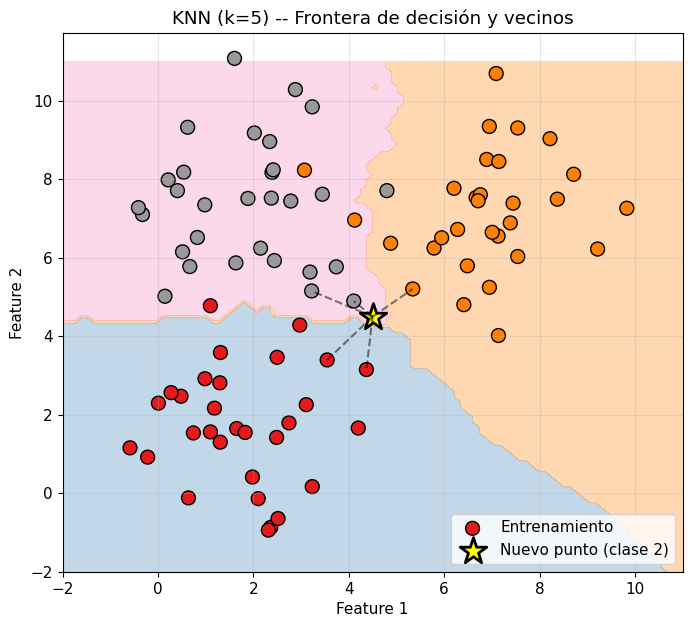

In [27]:
# === GRÁFICA: frontera de decisión KNN ===
fig, ax = plt.subplots(figsize=(8, 7))
ax.contourf(xx, yy, Z, alpha=0.3, cmap='Set1', levels=[-0.5, 0.5, 1.5, 2.5])
scatter = ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='Set1',
                     edgecolors='k', s=100, label='Entrenamiento')
ax.scatter(*x_test, marker='*', s=400, c='yellow', edgecolors='black', linewidth=2,
           label=f'Nuevo punto (clase {pred})')
# Dibujar los K vecinos mas cercanos
dists = np.sqrt(np.sum((X_train - x_test)**2, axis=1))
idx_k = np.argsort(dists)[:5]
for i in idx_k:
    ax.plot([x_test[0], X_train[i, 0]], [x_test[1], X_train[i, 1]], 'k--', alpha=0.5)
ax.set_title('KNN (k=5) -- Frontera de decisión y vecinos')
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2'); ax.legend(); ax.grid(alpha=0.3)
plt.show()


# [SK] 1.6 KNN -- scikit-learn

## Ejemplo

Clasificar especies de flores iris (setosa, versicolor, virginica) según las dimensiones del sepalo y petalo. Es el dataset clásico de Fisher (1936), con 150 muestras y 4 features.

## Qué se aprende

- A usar `KNeighborsClassifier` de sklearn.
- A estudiar como varian la **accuracy** con k (la curva de complejidad) y a elegir el k óptimo.
- Qué KNN es sensible a la escala: si una feature tiene rango 0-1000 y otra 0-1, la primera dominara la distancia.


In [28]:
# === 1.6 KNN -- scikit-learn ===
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris()
X = iris.data[:, :2]  # sepalo (largo, ancho) para GRÁFICAr
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.1f}%")


Accuracy: 80.0%


In [29]:
# === GRÁFICA: K vs Accuracy (curva interactiva) ===
k_range = range(1, 26)
scores = [KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
                                          .score(X_test, y_test)
          for k in k_range]

fig = go.Figure()
fig.add_trace(go.Scatter(x=list(k_range), y=scores, mode='lines+markers',
                         marker=dict(size=10, color=scores, colorscale='Viridis',
                                     showscale=True),
                         line=dict(color='#1f77b4')))
fig.update_layout(title='KNN -- Accuracy según número de vecinos (k)',
                  xaxis_title='k (número de vecinos)', yaxis_title='Accuracy en test',
                  template='plotly_white', width=750, height=450)
fig.show()


# [PY] 1.7 Árbol de Decisión -- Python puro

## Ejemplo

Un árbol de decisión es como un diagrama de flujo: hace preguntas binarias ("edad <= 40?") y según la respuesta baja por una rama u otra. Son muy interpretables y manejan bien features mixtas (númericas y categóricas).

## Qué se aprende

- El concepto de **impureza de Gini** (definido en el glosario): cuan mezcladas están las clases en un nodo.
- Como se construye el árbol recursivamente: en cada nodo se busca el corte (feature + umbral) Qué **maximiza la ganancia de información**.
- La noción de **profundidad máxima** como control de sobreajuste.

## Dataset sintético

Decidir si comprar (1) o no comprar (0) un producto según edad y salario. Regla oculta: compran los mayores de 40 con salario > 50k.


In [30]:
# === 1.7 ARBOL DE DECISION -- Python puro ===
np.random.seed(42)
n = 100
edad = np.random.randint(20, 65, n)
salario = np.random.randint(15, 100, n)
# Regla oculta: compra si edad > 40 Y salario > 50
y = ((edad > 40) & (salario > 50)).astype(int) | (np.random.rand(n) < 0.1).astype(int)
y = np.clip(y, 0, 1)

X = np.column_stack([edad, salario])

def gini(y):
    if len(y) == 0: return 0
    p = np.bincount(y, minlength=2) / len(y)
    return 1 - np.sum(p**2)

def best_split(X, y):
    best_gain, best_feat, best_thr = -1, 0, 0
    parent_gini = gini(y)
    n = len(y)
    for feat in range(X.shape[1]):
        thresholds = np.unique(X[:, feat])
        for thr in thresholds:
            left = y[X[:, feat] <= thr]
            right = y[X[:, feat] > thr]
            if len(left) == 0 or len(right) == 0: continue
            child_gini = (len(left)/n)*gini(left) + (len(right)/n)*gini(right)
            gain = parent_gini - child_gini
            if gain > best_gain:
                best_gain, best_feat, best_thr = gain, feat, thr
    return best_feat, best_thr, best_gain

class Node:
    def __init__(self, feat=None, thr=None, left=None, right=None, value=None):
        self.feat, self.thr, self.left, self.right, self.value = feat, thr, left, right, value

def build_tree(X, y, depth=0, max_depth=3):
    if depth >= max_depth or len(set(y)) == 1 or len(y) < 5:
        return Node(value=Counter(y).most_common(1)[0][0])
    feat, thr, gain = best_split(X, y)
    if gain == 0:
        return Node(value=Counter(y).most_common(1)[0][0])
    left_mask = X[:, feat] <= thr
    return Node(feat, thr,
                build_tree(X[left_mask], y[left_mask], depth+1, max_depth),
                build_tree(X[~left_mask], y[~left_mask], depth+1, max_depth))

def predict_tree(node, x):
    while node.value is None:
        node = node.left if x[node.feat] <= node.thr else node.right
    return node.value

tree = build_tree(X, y, max_depth=3)
y_pred = np.array([predict_tree(tree, x) for x in X])
print(f"Accuracy (entrenamiento): {np.mean(y_pred == y)*100:.1f}%")
print(f"División raíz: feature {'edad' if tree.feat==0 else 'salario'} <= {tree.thr}")


Accuracy (entrenamiento): 96.0%
División raíz: feature edad <= 40


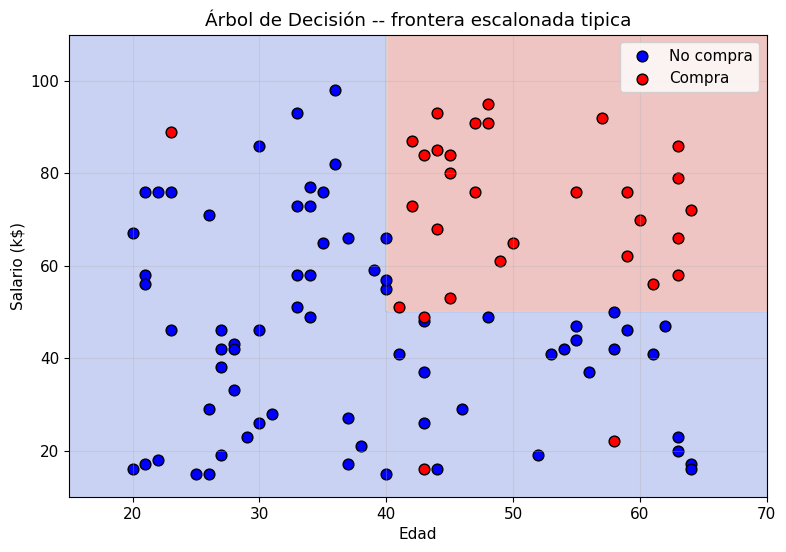

In [31]:
# === GRÁFICA: frontera del árbol ===
xx, yy = np.meshgrid(np.linspace(15, 70, 200), np.linspace(10, 110, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = np.array([predict_tree(tree, p) for p in grid]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
ax.scatter(X[y==0, 0], X[y==0, 1], c='blue', s=60, edgecolors='k', label='No compra')
ax.scatter(X[y==1, 0], X[y==1, 1], c='red', s=60, edgecolors='k', label='Compra')
ax.set_xlabel('Edad'); ax.set_ylabel('Salario (k$)')
ax.set_title('Árbol de Decisión -- frontera escalonada tipica')
ax.legend(); ax.grid(alpha=0.3)
plt.show()


# [SK] 1.8 Árbol de Decisión -- scikit-learn

## Ejemplo

Mismo dataset Iris, pero ahora usamos las 4 features. Visualizaremos el árbol completo para entender qué decisiones toma el modelo.

## Qué se aprende

- A leer un árbol: cada nodo muestra la condición de corte, el Gini, el número de muestras y la clase mayoritaria.
- El concepto de **importancia de features**: cuanto se usa cada feature para reducir la impureza, acumulado en todos los nodos.
- Qué un árbol muy profundo sobreajusta; por eso `max_depth=3`.


In [32]:
# === 1.8 ARBOL DE DECISION -- scikit-learn ===
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X_train, y_train)
print(f"Accuracy: {tree_clf.score(X_test, y_test)*100:.1f}%")
print(f"Importancia de features: {dict(zip(iris.feature_names, tree_clf.feature_importances_.round(3)))}")


Accuracy: 97.8%
Importancia de features: {'sepal length (cm)': np.float64(0.0), 'sepal width (cm)': np.float64(0.0), 'petal length (cm)': np.float64(0.551), 'petal width (cm)': np.float64(0.449)}


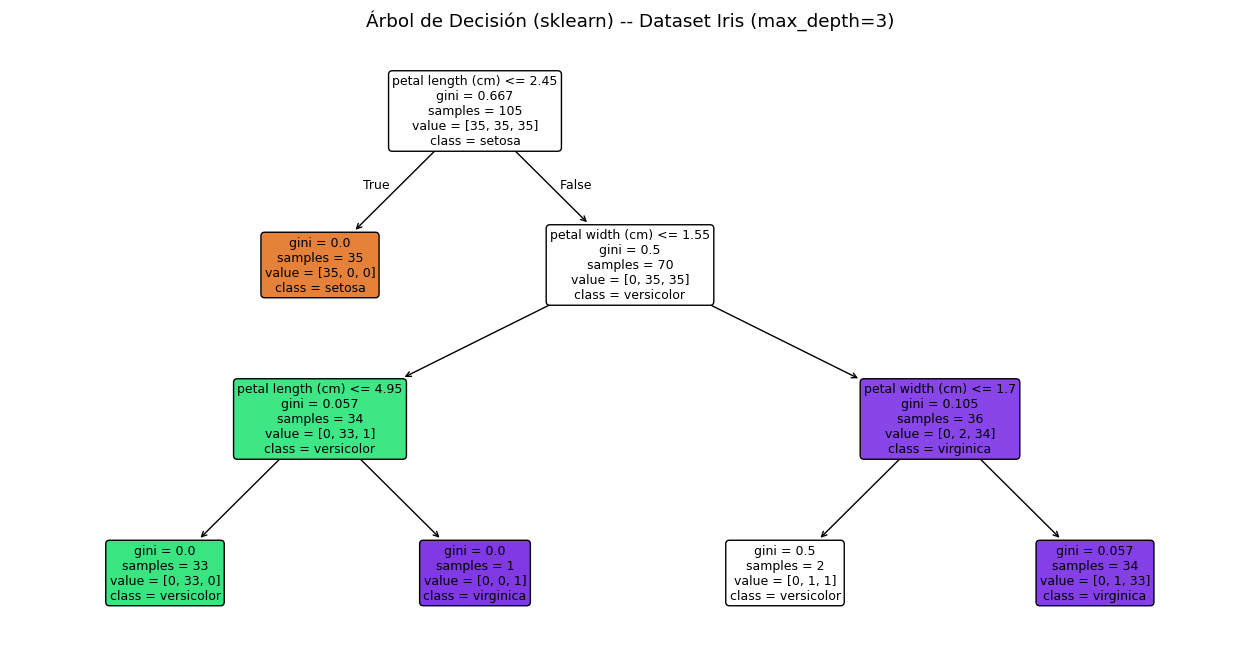

In [33]:
# === GRÁFICA: árbol visualizado ===
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree_clf, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True, rounded=True, ax=ax, fontsize=9)
plt.title('Árbol de Decisión (sklearn) -- Dataset Iris (max_depth=3)')
plt.show()


# [PY] 1.9 Naive Bayes -- Python puro

## Ejemplo

Filtrado de spam: dado un correo con ciertas palabras, es spam o no? Naive Bayes es uno de los clasificadores mas clasicos para este problema (y uno de los primeros en usarse en producción).

## Qué se aprende

- El **teorema de Bayes**: $P(y | x) \propto P(y) \cdot P(x | y)$.
- El supuesto "naive" (ingenuo): las features son **independientes entre si** dado y. Esto casi nunca es cierto en la práctica, pero el clasificador funciona sorprendentemente bien.
- Para features continuas se asume qué cada una sigue una **distribución Gaussiana** por clase (GaussianNB).


In [34]:
# === 1.9 NAIVE BAYES GAUSSIANO -- Python puro ===
np.random.seed(42)
# Clase 0: centro (2,2), Clase 1: centro (6,6)
X0 = np.random.randn(60, 2) * 1.0 + [2, 2]
X1 = np.random.randn(60, 2) * 1.5 + [6, 6]
X_nb = np.vstack([X0, X1])
y_nb = np.array([0]*60 + [1]*60)

# Estimar parámetros por clase: media, varianza y prior
def fit_gnb(X, y):
    classes = np.unique(y)
    params = {}
    for c in classes:
        Xc = X[y == c]
        params[c] = {'mean': Xc.mean(axis=0), 'var': Xc.var(axis=0), 'prior': len(Xc)/len(y)}
    return params

def predict_gnb(params, X):
    preds = []
    for x in X:
        probs = {}
        for c, p in params.items():
            # log-likelihood gaussiano
            ll = -0.5 * np.sum(np.log(2*np.pi*p['var']) + (x - p['mean'])**2 / p['var'])
            probs[c] = np.log(p['prior']) + ll
        preds.append(max(probs, key=probs.get))
    return np.array(preds)

params = fit_gnb(X_nb, y_nb)
y_pred = predict_gnb(params, X_nb)
print(f"Accuracy: {np.mean(y_pred == y_nb)*100:.1f}%")
print("Parámetros estimados:")
for c, p in params.items():
    print(f"  Clase {c}: media={p['mean'].round(2)}, var={p['var'].round(2)}, prior={p['prior']:.2f}")


Accuracy: 100.0%
Parámetros estimados:
  Clase 0: media=[1.87 1.97], var=[0.75 0.95], prior=0.50
  Clase 1: media=[5.94 6.28], var=[1.88 2.63], prior=0.50


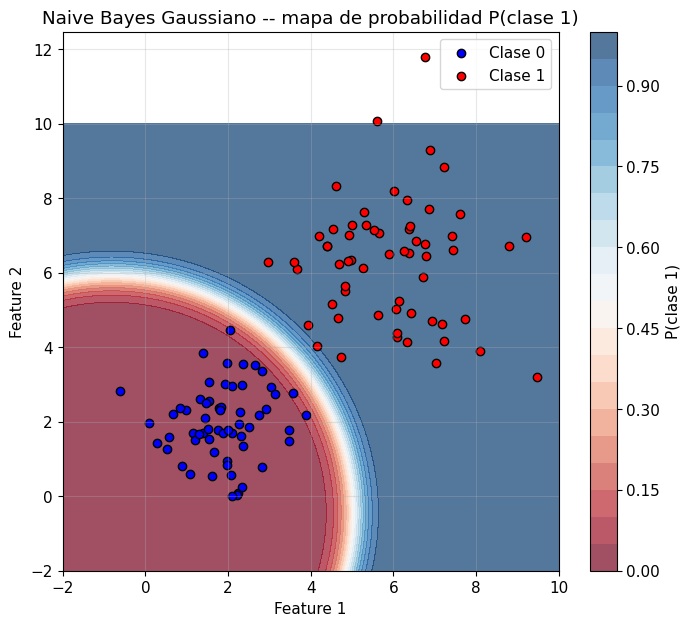

In [35]:
# === GRÁFICA: probabilidades por clase en el espacio 2D ===
xx, yy = np.meshgrid(np.linspace(-2, 10, 150), np.linspace(-2, 10, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = np.zeros((len(grid), 2))
for i, x in enumerate(grid):
    for c, p in params.items():
        ll = -0.5 * np.sum(np.log(2*np.pi*p['var']) + (x - p['mean'])**2 / p['var'])
        probs[i, c] = np.exp(np.log(p['prior']) + ll)
probs = probs / probs.sum(axis=1, keepdims=True)
Z = probs[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 7))
cf = ax.contourf(xx, yy, Z, levels=20, cmap='RdBu', alpha=0.7)
plt.colorbar(cf, label='P(clase 1)')
ax.scatter(X0[:, 0], X0[:, 1], c='blue', edgecolors='k', label='Clase 0')
ax.scatter(X1[:, 0], X1[:, 1], c='red', edgecolors='k', label='Clase 1')
ax.set_title('Naive Bayes Gaussiano -- mapa de probabilidad P(clase 1)')
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2'); ax.legend(); ax.grid(alpha=0.3)
plt.show()


# [SK] 1.10 Naive Bayes -- scikit-learn

## Ejemplo

Mismo dataset Iris, pero ahora comparamos Naive Bayes con el Árbol de Decisión (ejemplo 1.8) usando **validación cruzada 5-fold**.

## Qué se aprende

- A usar `cross_val_score` para obtener una estimación robusta del rendimiento.
- A comparar dos modelos con la misma métrica en el mismo dataset, en lugar de un solo número.
- Qué Naive Bayes es muy rápido y funciona bien incluso con pocos datos, aunQué su supuesto de independencia sea violado.


In [36]:
# === 1.10 NAIVE BAYES -- scikit-learn ===
from sklearn.naive_bayes import GaussianNB

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

nb = GaussianNB()
nb.fit(X_train, y_train)
print(f"Accuracy test: {nb.score(X_test, y_test)*100:.1f}%")

# Validación cruzada 5-fold
cv_scores = cross_val_score(nb, X, y, cv=5)
print(f"CV 5-fold: {cv_scores.mean()*100:.1f}% +/- {cv_scores.std()*100:.1f}%")


Accuracy test: 91.1%
CV 5-fold: 95.3% +/- 2.7%


In [37]:
# === GRÁFICA: comparación GaussianNB vs Árbol ===
from sklearn.tree import DecisionTreeClassifier

nb_scores = cross_val_score(GaussianNB(), X, y, cv=5)
tree_scores = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), X, y, cv=5)

df_cmp = pd.DataFrame({
    'Fold': list(range(1, 6)) * 2,
    'Accuracy': np.concatenate([nb_scores, tree_scores]),
    'Modelo': ['GaussianNB']*5 + ['Árbol Dec.']*5
})

fig = px.bar(df_cmp, x='Fold', y='Accuracy', color='Modelo', barmode='group',
             title='Naive Bayes vs Árbol de Decisión -- Iris (5-fold CV)',
             text_auto='.3f', template='plotly_white',
             color_discrete_map={'GaussianNB': '#1f77b4', 'Árbol Dec.': '#ff7f0e'})
fig.update_yaxes(range=[0.7, 1.0])
fig.show()


# Resumen

## Lo qué cubrimos en 10 ejemplos

| # | Algoritmo | Python puro | scikit-learn |
|---|-----------|:-----------:|:------------:|
| 1 | Regresión Lineal | si | si (California Housing) |
| 2 | Regresión Logística | si | si (Breast Cancer) |
| 3 | KNN | si | si (Iris) |
| 4 | Árbol de Decisión | si | si (Iris) |
| 5 | Naive Bayes | si | si (Iris) |

## Métricas y conceptos vistos

- **Regresión**: MSE, RMSE, R^2
- **Clasificacion**: Accuracy, Precision, Recall, F1-score, matriz de confusión, Gini, ganancia de información
- **Evaluación**: validación cruzada k-fold

## Reflexiones

1. **Python puro vs scikit-learn**: implementar a mano ayuda a entender la intuición matemática; scikit-learn ahorra tiempo en producción.
2. **Eleccion de algoritmo**: no existe uno universal. Depende del tipo de datos, complejidad y necesidad de interpretabilidad.
   - Si tienes pocas features y necesitas interpretabilidad: árbol de decisión.
   - Si tienes muchas features lineales: regresión Logística o Naive Bayes.
3. **Visualizacion**: las GRÁFICAs interactivas (Plotly) y Animaciónes revelan dinamicas Qué un número solo no muestra.

## Estudiar como complemento

- Estudiar **Random Forest** y **Gradient Boosting** (XGBoost, LightGBM) como evolución de los árboles.
- Continuar con el cuaderno de **Aprendizaje No Supervisado** (K-Means, PCA, DBSCAN, etc.).

---

*Cuaderno generado para fines educativos.*
